# Chapter 6 — Advanced Logistic Regression and Extensions
**Reference:** *scikit-learn Cookbook, Third Edition* — John Sukup  
**Environment:** Google Colab / Jupyter Notebook

This notebook explores logistic regression for binary and multiclass classification, regularization, class weighting, and model evaluation.

## 1. Theory: logistic regression

Despite its name, logistic regression is commonly used for **classification**. For binary classification, it estimates the probability of class 1 with the sigmoid function:

\[
P(y=1\mid x)=\frac{1}{1+e^{-(\beta_0+\beta^Tx)}}
\]

The default decision threshold is 0.5, but it can be adjusted depending on the costs of false positives and false negatives. Regularization controls coefficient magnitude. Logistic regression can also handle multiclass classification.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification, load_iris
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report,
    ConfusionMatrixDisplay, roc_curve, roc_auc_score, precision_score, recall_score)
RANDOM_STATE = 42

X, y = make_classification(n_samples=900, n_features=12, n_informative=7,
    n_redundant=2, weights=[0.62, 0.38], class_sep=1.0, random_state=RANDOM_STATE)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Training class proportions:", pd.Series(y_train).value_counts(normalize=True).sort_index().round(3).to_dict())

Train: (675, 12) | Test: (225, 12)
Training class proportions: {0: 0.618, 1: 0.382}


## 2. Fit and evaluate a binary logistic regression model

In [2]:
model = make_pipeline(StandardScaler(),
    LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]
print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}")
print(f"ROC AUC: {roc_auc_score(y_test, y_prob):.3f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.809
ROC AUC: 0.878

Classification report:
              precision    recall  f1-score   support

           0       0.86      0.83      0.84       139
           1       0.74      0.78      0.76        86

    accuracy                           0.81       225
   macro avg       0.80      0.80      0.80       225
weighted avg       0.81      0.81      0.81       225



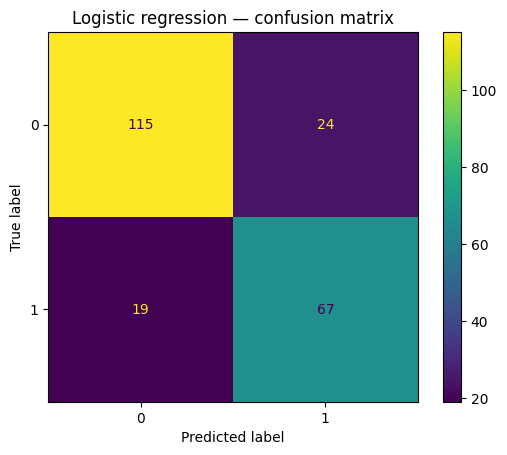

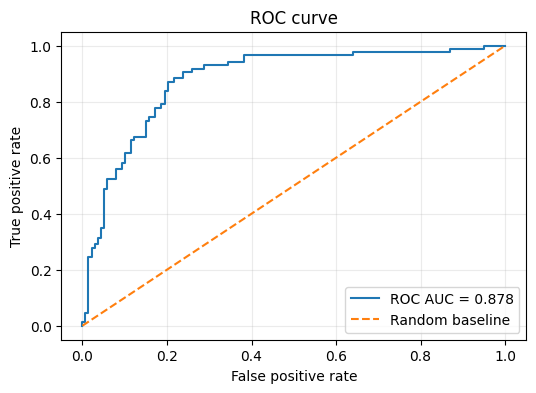

In [3]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Logistic regression — confusion matrix")
plt.show()
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label=f"ROC AUC = {roc_auc_score(y_test, y_prob):.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curve"); plt.legend(); plt.grid(alpha=0.25); plt.show()

**Interpretation:** accuracy is the fraction of correct predictions. Precision and recall describe different kinds of positive-class errors. ROC AUC evaluates ranking across thresholds. Choose metrics based on class balance and the consequences of mistakes.

## 3. Regularization and hyperparameter tuning

In [4]:
pipe = make_pipeline(StandardScaler(),
    LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
param_grid = {
    "logisticregression__C": [0.01, 0.1, 1.0, 10.0, 100.0],
    "logisticregression__class_weight": [None, "balanced"]
}
search = GridSearchCV(pipe, param_grid, scoring="roc_auc",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=-1)
search.fit(X_train, y_train)
print("Best parameters:", search.best_params_)
print(f"Best mean CV ROC AUC: {search.best_score_:.3f}")
best = search.best_estimator_
p = best.predict_proba(X_test)[:, 1]
pred = best.predict(X_test)
print(f"Test accuracy: {accuracy_score(y_test, pred):.3f}")
print(f"Test ROC AUC: {roc_auc_score(y_test, p):.3f}")

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Best parameters: {'logisticregression__C': 10.0, 'logisticregression__class_weight': 'balanced'}
Best mean CV ROC AUC: 0.913
Test accuracy: 0.822
Test ROC AUC: 0.879


`C` is inverse regularization strength: smaller values mean stronger regularization. `class_weight="balanced"` adjusts weights inversely to class frequencies and may help with imbalance, but should be evaluated with task-appropriate metrics.

## 4. Decision thresholds and multiclass classification

In [5]:
threshold = 0.35
pred_lower_threshold = (p >= threshold).astype(int)
print("Default threshold (0.5): precision =", round(precision_score(y_test, pred), 3),
      "| recall =", round(recall_score(y_test, pred), 3))
print(f"Threshold ({threshold}): precision =", round(precision_score(y_test, pred_lower_threshold), 3),
      "| recall =", round(recall_score(y_test, pred_lower_threshold), 3))

iris = load_iris()
Xm_train, Xm_test, ym_train, ym_test = train_test_split(
    iris.data, iris.target, test_size=0.25, stratify=iris.target, random_state=RANDOM_STATE)
multi = make_pipeline(StandardScaler(),
    LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
multi.fit(Xm_train, ym_train)
ym_pred = multi.predict(Xm_test)
print("\nIris multiclass accuracy:", round(accuracy_score(ym_test, ym_pred), 3))
print(classification_report(ym_test, ym_pred, target_names=iris.target_names))

Default threshold (0.5): precision = 0.725 | recall = 0.86
Threshold (0.35): precision = 0.669 | recall = 0.919

Iris multiclass accuracy: 0.921
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       0.86      0.92      0.89        13
   virginica       0.92      0.85      0.88        13

    accuracy                           0.92        38
   macro avg       0.92      0.92      0.92        38
weighted avg       0.92      0.92      0.92        38



## 5. Hands-on exercises

1. Change `C` and record how cross-validation ROC AUC changes.
2. Compare `class_weight=None` and `"balanced"` on the imbalanced dataset.
3. Try decision thresholds of 0.25, 0.35, 0.5, and 0.65; compare precision and recall.
4. Inspect multiclass probability predictions with `predict_proba`.
5. Explain why accuracy can be misleading when one class is much more common.

## 6. Chapter summary

- Logistic regression estimates class probabilities.
- Scaling and regularization help build stable models.
- `C` controls inverse regularization strength.
- Class weights and decision thresholds can change the precision–recall trade-off.
- Evaluate with confusion matrices, precision, recall, F1, and ROC AUC as appropriate.